## Latihan Mandiri 4 - Pertemuan 7: Asyncio - Pemrograman Asinkron

**Nama: Shahida Shintya   
NIM: 2411511007**


## 1. Eksperimen Skala

**Soal:** Perbesar `daftar_paket_banyak` menjadi 20–30 nama paket PyPI valid (cari sendiri nama-nama package populer). Bandingkan waktu total untuk `BATAS_KONKURENSI` = 1, 3, 5, 10, 20. Plot waktu vs batas konkurensi. Pada titik berapa penambahan batas konkurensi mulai memberi manfaat yang sangat kecil? Kaitkan dengan konsep *diminishing returns* dari Hukum Amdahl (Pertemuan 1).

**Jawaban :**
daftar_paket_banyak yang digunakan,yaitu 25 paket PyPI dimana tiap batas dijalankan 3 kali lalu dirata-rata, dan ada satu kali pemanasan di awal yang tidak dihitung.



In [2]:
import aiohttp
import asyncio
import time

daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django",
    "scipy", "matplotlib", "pillow", "sqlalchemy", "pytest", "beautifulsoup4",
    "lxml", "jinja2", "click", "werkzeug", "urllib3", "certifi",
    "pydantic", "fastapi", "uvicorn", "boto3", "scikit-learn", "tqdm", "pyyaml",
]
print("Jumlah paket:", len(daftar_paket_banyak))

async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with session.get(url) as response:
        data = await response.json()
        info = data["info"]
        return {
            "nama": info["name"],
            "versi": info["version"],
            "summary": (info["summary"] or "")[:60],
        }

async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:  # hanya N coroutine yang boleh masuk bersamaan
        return await ambil_metadata_paket(session, nama_paket)

async def jalankan(batas):
    semaphore = asyncio.Semaphore(batas)
    start = time.perf_counter()
    async with aiohttp.ClientSession() as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak],
            return_exceptions=True,
        )
    waktu = time.perf_counter() - start
    gagal = sum(isinstance(h, Exception) for h in hasil)
    return waktu, gagal

Jumlah paket: 25


In [3]:
BATAS_UJI = [1, 3, 5, 10, 20]
ULANG = 3

await jalankan(5)  # pemanasan, hasilnya tidak dipakai

rata_waktu = []
for batas in BATAS_UJI:
    percobaan = []
    for _ in range(ULANG):
        waktu, gagal = await jalankan(batas)
        percobaan.append(waktu)
    rata = sum(percobaan) / len(percobaan)
    rata_waktu.append(rata)
    print(f"Batas {batas:>2} | rata-rata {rata:.2f} detik | gagal pada percobaan terakhir: {gagal}")

Batas  1 | rata-rata 2.30 detik | gagal pada percobaan terakhir: 0
Batas  3 | rata-rata 1.42 detik | gagal pada percobaan terakhir: 0
Batas  5 | rata-rata 1.55 detik | gagal pada percobaan terakhir: 0
Batas 10 | rata-rata 1.31 detik | gagal pada percobaan terakhir: 0
Batas 20 | rata-rata 1.28 detik | gagal pada percobaan terakhir: 0


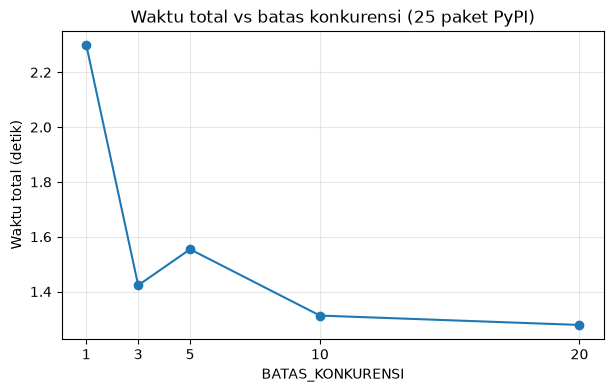

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(BATAS_UJI, rata_waktu, marker="o")
plt.xticks(BATAS_UJI)
plt.xlabel("BATAS_KONKURENSI")
plt.ylabel("Waktu total (detik)")
plt.title("Waktu total vs batas konkurensi (25 paket PyPI)")
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Hitung speedup dan penurunan waktu tiap kenaikan batas
print(f"{'Batas':>5} | {'Waktu (dtk)':>11} | {'Speedup':>7} | {'Turun dari sebelumnya':>21}")
titik = None
for i, (b, w) in enumerate(zip(BATAS_UJI, rata_waktu)):
    speedup = rata_waktu[0] / w
    if i == 0:
        turun = "-"
    else:
        persen = (rata_waktu[i - 1] - w) / rata_waktu[i - 1] * 100
        turun = f"{persen:.0f}%"
        if titik is None and persen < 20:
            titik = b
    print(f"{b:>5} | {w:>11.2f} | {speedup:>6.2f}x | {turun:>21}")

print()
if titik:
    print(f"Manfaat mulai kecil (turun < 20%) di batas = {titik}")
else:
    print("Belum ada batas yang penurunannya di bawah 20%.")

Batas | Waktu (dtk) | Speedup | Turun dari sebelumnya
    1 |        2.30 |   1.00x |                     -
    3 |        1.42 |   1.62x |                   38%
    5 |        1.55 |   1.48x |                   -9%
   10 |        1.31 |   1.75x |                   16%
   20 |        1.28 |   1.80x |                    3%

Manfaat mulai kecil (turun < 20%) di batas = 5


Berdasarkan hasil percobaan, waktu eksekusi mengalami penurunan yang cukup besar ketika batas konkurensi dinaikkan dari 1 menjadi 3 atau 5. Namun, setelah itu, penurunan waktu semakin kecil. Berdasarkan tabel pengujian, titik ketika peningkatan mulai kurang signifikan umumnya berada pada batas 5–10, meskipun hasilnya dapat berbeda tergantung kondisi jaringan. Hal ini sesuai dengan konsep diminishing returns dalam Hukum Amdahl, yang dijelaskan melalui rumus \\(Speedup = \frac{1}{(1-P)+P/N}\\). Peningkatan kecepatan tetap terbatas karena ada proses yang berjalan berurutan, seperti membuka koneksi dan membaca JSON, serta adanya batas kemampuan server. Jadi, batas konkurensi sekitar 5–10 dapat dianggap cukup karena penambahan batas di atasnya tidak memberikan peningkatan yang terlalu besar.

## 2. Deteksi Blocking Call

**Soal:** Buat 3 coroutine berbeda: satu memakai `asyncio.sleep()`, satu memakai `time.sleep()`, dan satu lagi memakai operasi CPU-bound murni (misalnya hitung faktorial dari angka besar dalam loop, tanpa `await` sama sekali). Jalankan ketiganya dengan `asyncio.gather()` bersama satu coroutine `asyncio.sleep()` lain sebagai "pengukur". Amati dan jelaskan coroutine mana saja yang mengganggu jalannya coroutine pengukur, dan mengapa.

**Jawaban :**
`pengukur` tidur 0.1 detik berulang kali dan mencatat jeda sebenarnya. Kalau jedanya tetap sekitar 0.10 detik, event loop lancar. Kalau jedanya besar, ada yang menahan event loop.


In [11]:
import asyncio
import time

DURASI = 2  # detik

async def pakai_asyncio_sleep():
    await asyncio.sleep(DURASI)      # non-blocking

async def pakai_time_sleep():
    time.sleep(DURASI)               # blocking: event loop berhenti

async def pakai_cpu_bound():
    hasil = 1
    for i in range(1, 90001):        # tidak ada await sama sekali
        hasil *= i                   # faktorial 90000, kira-kira 2 detik
    return hasil.bit_length()

async def pengukur(jumlah_tick=30, interval=0.1):
    jeda_nyata = []
    terakhir = time.perf_counter()
    for _ in range(jumlah_tick):
        await asyncio.sleep(interval)
        sekarang = time.perf_counter()
        jeda_nyata.append(sekarang - terakhir)
        terakhir = sekarang
    return jeda_nyata

In [7]:
async def uji(nama, korutin):
    start = time.perf_counter()
    jeda, _ = await asyncio.gather(pengukur(), korutin())
    total = time.perf_counter() - start
    print(f"{nama:<20} | jeda terbesar: {max(jeda):.2f} dtk | total: {total:.2f} dtk")

async def tidak_ada():
    pass

await uji("tanpa gangguan", tidak_ada)
await uji("asyncio.sleep()", pakai_asyncio_sleep)
await uji("time.sleep()", pakai_time_sleep)
await uji("CPU-bound (faktorial)", pakai_cpu_bound)

tanpa gangguan       | jeda terbesar: 0.12 dtk | total: 3.24 dtk
asyncio.sleep()      | jeda terbesar: 0.11 dtk | total: 3.19 dtk
time.sleep()         | jeda terbesar: 2.00 dtk | total: 5.14 dtk
CPU-bound (faktorial) | jeda terbesar: 3.25 dtk | total: 6.39 dtk


In [8]:
# Semuanya sekaligus, sesuai soal
start = time.perf_counter()
jeda, *_ = await asyncio.gather(
    pengukur(),
    pakai_asyncio_sleep(),
    pakai_time_sleep(),
    pakai_cpu_bound(),
)
total = time.perf_counter() - start

besar = [round(j, 2) for j in jeda if j > 0.3]
print(f"Total waktu         : {total:.2f} detik")
print(f"Jeda terbesar       : {max(jeda):.2f} detik")
print(f"Jeda di atas 0.3 dtk: {besar}")

Total waktu         : 8.38 detik
Jeda terbesar       : 5.21 detik
Jeda di atas 0.3 dtk: [5.21]


**Penjelasan:**

`asyncio.sleep()` tidak mengganggu coroutine lain karena memberikan kesempatan kepada coroutine lain untuk berjalan saat menunggu. Sebaliknya, `time.sleep()` menghentikan thread yang menjalankan event loop, sehingga coroutine lain ikut tertunda. Hal yang sama terjadi pada proses CPU-bound yang berjalan lama tanpa `await`, karena event loop tidak mendapat kesempatan untuk menjalankan coroutine lainnya. Perpindahan eksekusi antarcoroutine terjadi ketika proses memberikan kesempatan, misalnya melalui `await`. Oleh karena itu, gunakan `asyncio.sleep()` untuk proses menunggu dan pindahkan pekerjaan komputasi berat ke thread atau proses lain agar coroutine lain tetap bisa berjalan.

## 3. Producer-Multi-Consumer dengan Prioritas

**Soal:** Modifikasi contoh `asyncio.Queue` pada bagian 6.4 agar setiap item memiliki "prioritas" (angka 1–3), dan consumer harus memproses item berprioritas tinggi (angka lebih kecil) lebih dulu. (Hint: cari tahu tentang `asyncio.PriorityQueue`.)

**Jawaban :
Yang diubah dari contoh:
- `Queue` diganti `PriorityQueue`.
- Item jadi tuple `(prioritas, nomor_urut, isi)`. Nomor urut mencegah error kalau prioritasnya sama.
- Sinyal berhenti diberi prioritas 99 supaya diambil paling akhir.
- Producer dibuat cepat dan consumer lambat, supaya antrean menumpuk dan efek prioritasnya terlihat.

In [9]:
import asyncio
import random
import itertools

random.seed(42)
nomor = itertools.count()

JUMLAH_CONSUMER = 3
JUMLAH_ITEM = 12
PRIORITAS_BERHENTI = 99
diambil = []  # mencatat urutan item yang diambil consumer

async def producer(queue, jumlah_item):
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)
        await queue.put((prioritas, next(nomor), f"item-{i}"))
        print(f"[Producer] kirim item-{i} (prioritas {prioritas})")
        await asyncio.sleep(0.01)  # produksi cepat
    for _ in range(JUMLAH_CONSUMER):
        await queue.put((PRIORITAS_BERHENTI, next(nomor), None))

async def consumer(queue, nama):
    while True:
        prioritas, _, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        diambil.append(prioritas)
        print(f"    [{nama}] ambil {item} (prioritas {prioritas})")
        await asyncio.sleep(0.2)  # pemrosesan lambat
        queue.task_done()

queue = asyncio.PriorityQueue()
await asyncio.gather(
    producer(queue, JUMLAH_ITEM),
    *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)],
)
print("\nSelesai.")

[Producer] kirim item-0 (prioritas 3)
    [Consumer-0] ambil item-0 (prioritas 3)
[Producer] kirim item-1 (prioritas 1)
    [Consumer-1] ambil item-1 (prioritas 1)
[Producer] kirim item-2 (prioritas 1)
    [Consumer-2] ambil item-2 (prioritas 1)
[Producer] kirim item-3 (prioritas 3)
[Producer] kirim item-4 (prioritas 2)
[Producer] kirim item-5 (prioritas 1)
[Producer] kirim item-6 (prioritas 1)
[Producer] kirim item-7 (prioritas 1)
[Producer] kirim item-8 (prioritas 3)
[Producer] kirim item-9 (prioritas 1)
[Producer] kirim item-10 (prioritas 3)
[Producer] kirim item-11 (prioritas 3)
    [Consumer-0] ambil item-5 (prioritas 1)
    [Consumer-1] ambil item-6 (prioritas 1)
    [Consumer-2] ambil item-7 (prioritas 1)
    [Consumer-0] ambil item-9 (prioritas 1)
    [Consumer-1] ambil item-4 (prioritas 2)
    [Consumer-2] ambil item-3 (prioritas 3)
    [Consumer-0] ambil item-8 (prioritas 3)
    [Consumer-1] ambil item-10 (prioritas 3)
    [Consumer-2] ambil item-11 (prioritas 3)

Selesai.


3 item pertama langsung diambil karena antrean masih kosong. Setelah itu consumer mengambil item dengan angka prioritas paling kecil lebih dulu.

In [10]:
# Cek: setelah 3 item pertama, prioritas yang diambil harus naik/sama (tidak turun)
sisa = diambil[JUMLAH_CONSUMER:]
print("Prioritas yang diambil :", diambil)
print("Setelah 3 item pertama :", sisa)
print("Sudah terurut?         :", sisa == sorted(sisa))

Prioritas yang diambil : [3, 1, 1, 1, 1, 1, 1, 2, 3, 3, 3, 3]
Setelah 3 item pertama : [1, 1, 1, 1, 2, 3, 3, 3, 3]
Sudah terurut?         : True


**Penjelasan:**

`PriorityQueue` mengatur data berdasarkan nilai prioritas, sehingga angka terkecil akan dikeluarkan terlebih dahulu, yaitu 1, kemudian 2, dan terakhir 3. Pengaruh prioritas akan lebih terlihat ketika antrean berisi banyak data. Jika proses consumer lebih cepat daripada producer dalam menambahkan data, urutan keluarnya data bisa terlihat sama seperti antrean biasa. Kesimpulannya, penggunaan `PriorityQueue` cukup dilakukan dengan mengganti jenis antrean dan format item yang dimasukkan, sedangkan fungsi consumer tidak perlu diubah.


## 4. Refleksi Singkat (maks. 150 kata)

**Soal:** Bandingkan pengalaman kalian menulis kode paralel dengan `threading` (Pertemuan 2), `multiprocessing` (Pertemuan 3), dan `asyncio` (pertemuan ini) untuk kasus I/O-bound. Mana yang menurut kalian paling mudah dipahami dan mengapa? Berikan alasan berbasis pengalaman coding kalian, bukan hanya teori.

### Jawaban
Menurut saya, threading paling mudah dipahami untuk menangani pekerjaan I/O-bound karena penggunaannya sederhana dan kode lama bisa tetap digunakan dengan menambahkan `ThreadPoolExecutor`. Sebaliknya, multiprocessing lebih rumit karena perlu mengatur komunikasi data antarproses dan terkadang mengalami kendala di Jupyter.Saat belajar asyncio, saya pernah lupa menambahkan `await` sehingga coroutine tidak berjalan sesuai  harapan. Penggunaan `time.sleep()` juga dapat menghentikan coroutine lain. Selain itu, asyncio membutuhkan library yang mendukung operasi asynchronous, seperti `aiohttp`. Namun, setelah terbiasa, asyncio terasa lebih efisien untuk menangani banyak request sekaligus. Semaphore juga berguna untuk membatasi jumlah request yang berjalan bersamaan. threading cocok untuk pemula karena mudah diterapkan, sedangkan asyncio lebih sesuai untuk menangani banyak koneksi. Multiprocessing sebaiknya digunakan untuk pekerjaan CPU-bound yang membutuhkan komputasi berat. Pemilihan metode perlu disesuaikan dengan jenis pekerjaan serta apakah prosesnya bersifat blocking atau tidak.